# Stage C · one configuration, multiple entry points

**Assumed background:** Python functions, notebooks, pandas, and the earlier extraction. This notebook is now a scientific interface to reusable code. It loads the same reviewed TOML as `scripts/run_analysis.py`, names each table by its scientific role, and separates baseline from sensitivity results.

All input trials are synthetic, generated with seed 202611. The baseline uses inclusive 0.2–2.0 s RTs, includes errors, and gives participants equal weight. Restart and run all; compare the baseline with Stages A and B.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
project_root = next((p for p in (cwd, cwd.parent) if (p / "data/raw/trials.csv").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from motion-perception and open notebooks/; raw_trials CSV not found")
print("Python:", sys.executable)
print("Project:", project_root.name)

Python: workshop .venv (Python 3.11)
Project: motion-perception


In [2]:
from experiment.config import load_config
from experiment.preprocessing import load_trials, filter_trials
from experiment.analysis import participant_summary, condition_summary, choice_curve
from experiment.plotting import plot_results

## Load policy once, then pass explicit values

Paths inside TOML are relative to that file, so the notebook and script agree even when launched from different directories. The loader validates keys and bound values. Filtering and summary functions do not read configuration files or notebook globals.

In [3]:
config = load_config(project_root / "config/analysis.toml")
print({"config": config.config_path.name, "min_rt_s": config.min_rt_s,
       "max_rt_s": config.max_rt_s, "data": config.data_path.name})
raw_trials = load_trials(config.data_path)
filtered_trials = filter_trials(
    raw_trials, min_rt_s=config.min_rt_s, max_rt_s=config.max_rt_s
)
participant_metrics = participant_summary(filtered_trials)
condition_metrics = condition_summary(participant_metrics)
print(filtered_trials.groupby("condition").size().rename("retained_trials"))

{'config': 'analysis.toml', 'min_rt_s': 0.2, 'max_rt_s': 2.0, 'data': 'trials.csv'}
condition
clear    1886
noisy    1875
Name: retained_trials, dtype: int64


In [4]:
condition_metrics = condition_metrics.sort_values("condition").reset_index(drop=True)
print(condition_metrics.to_string(index=False))
print("SUMMARY_JSON=" + condition_metrics.to_json(orient="records", double_precision=15))
print("RETAINED=" + str(len(filtered_trials)))

condition  accuracy      sem  median_rt  n_participants
    clear  0.808111 0.009015   0.786242              24
    noisy  0.713384 0.009482   0.970044              24
SUMMARY_JSON=[{"condition":"clear","accuracy":0.808110967170552,"sem":0.009014669982837,"median_rt":0.786241666666667,"n_participants":24},{"condition":"noisy","accuracy":0.713383545700543,"sem":0.009481544947741,"median_rt":0.970043541666667,"n_participants":24}]
RETAINED=3761


## Present and interpret

Lines join empirical P(right) values by signed stimulus strength; no psychometric model is fitted. Condition error bars are descriptive participant intervals.

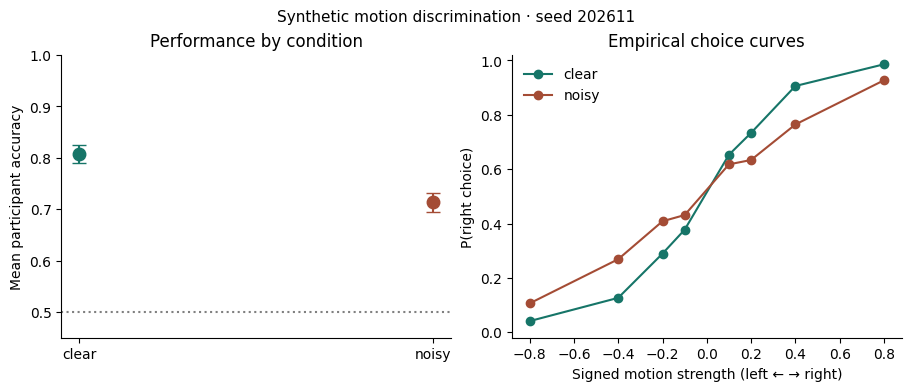

In [5]:
choice_probabilities = choice_curve(filtered_trials)
figure = plot_results(condition_metrics, choice_probabilities)
plt.show()
plt.close(figure)

## Sensitivity comparison · preserve the baseline

The alternative config raises the minimum RT to 0.6 s. This is an exploratory teaching example, not a scientifically justified replacement. Compare retained counts and condition accuracy while keeping baseline objects unchanged. The CLI writes the two configurations into separate output directories and records effective values in `run.json`.

In [6]:
sensitivity_config = load_config(project_root / "config/sensitivity.toml")
sensitivity_trials = filter_trials(
    raw_trials, min_rt_s=sensitivity_config.min_rt_s, max_rt_s=sensitivity_config.max_rt_s
)
sensitivity_metrics = condition_summary(participant_summary(sensitivity_trials))
print({"baseline_trials": len(filtered_trials), "sensitivity_trials": len(sensitivity_trials)})
comparison = condition_metrics[["condition", "accuracy"]].merge(
    sensitivity_metrics[["condition", "accuracy"]], on="condition", suffixes=("_baseline", "_sensitivity")
)
print(comparison.to_string(index=False))

{'baseline_trials': 3761, 'sensitivity_trials': 3461}
condition  accuracy_baseline  accuracy_sensitivity
    clear           0.808111              0.791955
    noisy           0.713384              0.713874


## Exercise · hand over a run, not just a figure

Create `config/rt-050.toml` with a 0.5 s minimum and a new output directory. Run it through the CLI. Inspect `run.json`, compare the input hash and software versions, and explain why the effective settings can differ from the source config if CLI overrides are supplied. Propose a focused Git commit and pull-request description.

<details><summary>Solution</summary>Keep the baseline TOML unchanged. Add the named alternative config and document its rationale. Run `python scripts/run_analysis.py --config config/rt-050.toml` from project root. Review `results/rt-050/run.json` and compare the CSV with the baseline. Commit the config and run instructions, not `.venv` or the generated result directory. Treat scientific justification separately from whether tests pass.</details>